[-4.         -3.2        -2.56       -2.048      -1.6384     -1.31072
 -1.048576   -0.8388608  -0.67108864 -0.53687091 -0.42949673 -0.34359738
 -0.27487791 -0.21990233 -0.17592186 -0.14073749 -0.11258999 -0.09007199
 -0.07205759 -0.05764608 -0.04611686]


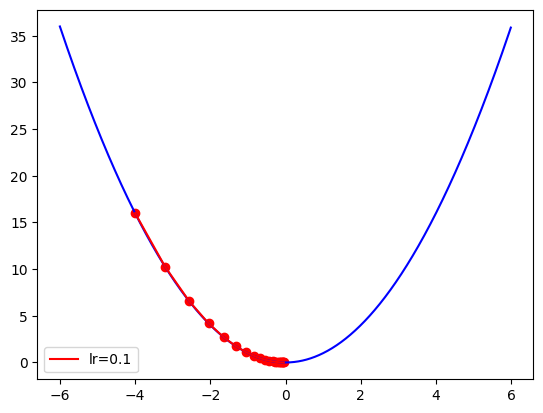

In [ ]:
# 匯入套件：numpy 負責數值運算，matplotlib 負責繪圖
import numpy as np
import matplotlib.pyplot as plt

# 目標函數：y = x^2，最小值在 x = 0
def func(x):
    return np.square(x)

# 目標函數的一階導數：dy/dx = 2x（梯度，指出函數上升最快的方向）
def dfunc(x):
    return 2 * x

def GD(x_start, df, epochs, lr):
    """梯度下降法：給定起始點與一階導函數，回傳 epochs 次迭代中 x 的每一步位置。
    :param x_start: x 的起始點
    :param df: 目標函數的一階導函數
    :param epochs: 迭代次數
    :param lr: 學習率（每一步走多遠）
    :return: x 在每次迭代後的位置（含起始點），長度為 epochs+1
    """
    xs = np.zeros(epochs + 1)   # 預先配置陣列，用來記錄每一步的 x
    x = x_start
    xs[0] = x                   # 第 0 筆存放起始點
    for i in range(epochs):
        dx = df(x)              # 計算目前位置的梯度
        v = -dx * lr            # 往梯度反方向走，步伐大小由學習率決定
        x += v                  # 更新 x：x_new = x - lr * f'(x)
        xs[i + 1] = x           # 記錄這一步的位置
    return xs

# ===== 主程式 =====
x_start = -4    # 起始權重（從負側出發，與課堂範例的 5 不同）
epochs = 20     # 迭代次數
lr = 0.1        # 學習率：太大會震盪或發散，太小則收斂很慢

# 執行梯度下降，取得每一步的 x
x = GD(x_start, dfunc, epochs, lr=lr)
print(x)

# ===== 繪圖 =====
color = 'r'
t = np.arange(-6.0, 6.0, 0.01)                        # 畫出完整的 y = x^2 曲線作為背景
plt.plot(t, func(t), c='b')
plt.plot(x, func(x), c=color, label='lr={}'.format(lr))  # 梯度下降走過的路徑
plt.scatter(x, func(x), c=color)                      # 標出每一步的位置
plt.legend()
plt.show()